In [1]:
!pip install mne

In [2]:
!pip install mne-icalabel

In [3]:
!pip install torch

In [4]:
import mne
import pandas as pd
import matplotlib.pyplot as plt
from mne.preprocessing import ICA
from mne_icalabel import label_components

In [5]:
file_path = "D:/Users/windows/Desktop/Inner Speech Decoding/Dataset/sub-01_ses-01_task-innerspeech_eeg.bdf"

raw = mne.io.read_raw_bdf(file_path, preload=True, verbose="WARNING")
raw

<RawEDF | sub-01_ses-01_task-innerspeech_eeg.bdf, 137 x 1875968 (1832.0 s), ~1.91 GiB, data loaded>

In [6]:
channels = raw.info['ch_names']
channels

['A1',
 'A2',
 'A3',
 'A4',
 'A5',
 'A6',
 'A7',
 'A8',
 'A9',
 'A10',
 'A11',
 'A12',
 'A13',
 'A14',
 'A15',
 'A16',
 'A17',
 'A18',
 'A19',
 'A20',
 'A21',
 'A22',
 'A23',
 'A24',
 'A25',
 'A26',
 'A27',
 'A28',
 'A29',
 'A30',
 'A31',
 'A32',
 'B1',
 'B2',
 'B3',
 'B4',
 'B5',
 'B6',
 'B7',
 'B8',
 'B9',
 'B10',
 'B11',
 'B12',
 'B13',
 'B14',
 'B15',
 'B16',
 'B17',
 'B18',
 'B19',
 'B20',
 'B21',
 'B22',
 'B23',
 'B24',
 'B25',
 'B26',
 'B27',
 'B28',
 'B29',
 'B30',
 'B31',
 'B32',
 'C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'C6',
 'C7',
 'C8',
 'C9',
 'C10',
 'C11',
 'C12',
 'C13',
 'C14',
 'C15',
 'C16',
 'C17',
 'C18',
 'C19',
 'C20',
 'C21',
 'C22',
 'C23',
 'C24',
 'C25',
 'C26',
 'C27',
 'C28',
 'C29',
 'C30',
 'C31',
 'C32',
 'D1',
 'D2',
 'D3',
 'D4',
 'D5',
 'D6',
 'D7',
 'D8',
 'D9',
 'D10',
 'D11',
 'D12',
 'D13',
 'D14',
 'D15',
 'D16',
 'D17',
 'D18',
 'D19',
 'D20',
 'D21',
 'D22',
 'D23',
 'D24',
 'D25',
 'D26',
 'D27',
 'D28',
 'D29',
 'D30',
 'D31',
 'D32',
 'EXG1',
 'E

In [7]:
# BioSemi 128 montage 불러오기
montage = mne.channels.make_standard_montage('biosemi128')

# montage 적용
raw.set_montage(montage, on_missing='ignore')  # EXG 채널은 위치 정보 없이 유지하고, EEG 채널만 montage를 적용

<RawEDF | sub-01_ses-01_task-innerspeech_eeg.bdf, 137 x 1875968 (1832.0 s), ~1.92 GiB, data loaded>

In [8]:
# montage 정보 출력
print(raw.get_montage())

<DigMontage | 0 extras (headshape), 0 HPIs, 3 fiducials, 136 channels>


In [9]:
print(raw.info['dig'])     # 빈 리스트([])면 안됨

[<DigPoint |        LPA : (-86.1, -0.0, 0.0) mm     : head frame>, <DigPoint |     Nasion : (0.0, 86.1, 0.0) mm       : head frame>, <DigPoint |        RPA : (86.1, 0.0, 0.0) mm       : head frame>, <DigPoint |     EEG #1 : (0.0, 0.0, 135.1) mm      : head frame>, <DigPoint |     EEG #2 : (0.0, -18.1, 133.4) mm    : head frame>, <DigPoint |     EEG #3 : (0.0, -37.1, 127.6) mm    : head frame>, <DigPoint |     EEG #4 : (0.0, -53.1, 118.9) mm    : head frame>, <DigPoint |     EEG #5 : (-26.7, -62.9, 106.1) mm  : head frame>, <DigPoint |     EEG #6 : (-48.3, -48.3, 106.1) mm  : head frame>, <DigPoint |     EEG #7 : (-56.3, -56.3, 91.9) mm   : head frame>, <DigPoint |     EEG #8 : (-52.1, -71.8, 74.2) mm   : head frame>, <DigPoint |     EEG #9 : (-55.0, -75.7, 56.6) mm   : head frame>, <DigPoint |    EEG #10 : (-55.8, -76.8, 36.8) mm   : head frame>, <DigPoint |    EEG #11 : (-54.4, -74.9, 18.8) mm   : head frame>, <DigPoint |    EEG #12 : (-50.6, -69.7, 0.0) mm    : head frame>, <DigPoint

In [10]:
events = mne.find_events(raw, shortest_event=1, verbose=True)

Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1112 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]


In [11]:
print(events)

[[   6283       0      11]
 [  16591       0      13]
 [  31976       0      14]
 ...
 [1829105       0      46]
 [1829126       0      16]
 [1829156       0      12]]


In [12]:
# Re-referencing
raw.set_eeg_reference(ref_channels=['EXG1', 'EXG2'])

EEG channel type selected for re-referencing
Applying a custom ('EEG',) reference.


<RawEDF | sub-01_ses-01_task-innerspeech_eeg.bdf, 137 x 1875968 (1832.0 s), ~1.92 GiB, data loaded>

In [13]:
eeg_d = raw.get_data()
eeg_d

array([[-2.35148003e-03, -2.35246440e-03, -2.35110503e-03, ...,
        -3.26463459e-03, -3.26415022e-03, -3.26793146e-03],
       [-1.38929431e-03, -1.38843493e-03, -1.38729431e-03, ...,
        -1.12838854e-03, -1.12740417e-03, -1.13134166e-03],
       [-2.30501137e-03, -2.30671449e-03, -2.30504262e-03, ...,
        -1.49366912e-03, -1.49212224e-03, -1.49530974e-03],
       ...,
       [-1.33398660e-02, -1.33194754e-02, -1.32998973e-02, ...,
        -1.22598055e-02, -1.22193212e-02, -1.22230712e-02],
       [-1.30762727e-02, -1.30856946e-02, -1.30888039e-02, ...,
        -1.05180899e-02, -1.04902619e-02, -1.04565119e-02],
       [ 6.55360000e+04,  6.55360000e+04,  6.55360000e+04, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00]])

In [14]:
eeg_d.shape

(137, 1875968)

In [15]:
channel_names = raw.ch_names

# NumPy 배열을 DataFrame으로 변환
df = pd.DataFrame(eeg_d.T, columns=channel_names)
df

,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,...,D32,EXG1,EXG2,EXG3,EXG4,EXG5,EXG6,EXG7,EXG8,Status
0,-0.002351,-0.001389,-0.002305,-0.002834,-0.007268,0.000217,-0.010027,-0.008167,-0.004082,-0.008715,...,-0.011488,0.002094,-0.002094,-0.005021,-0.016785,-0.008309,-0.027737,-0.013340,-0.013076,65536.0
1,-0.002352,-0.001388,-0.002307,-0.002835,-0.007268,0.000219,-0.010027,-0.008167,-0.004080,-0.008713,...,-0.011490,0.002096,-0.002096,-0.005017,-0.016786,-0.008309,-0.027727,-0.013319,-0.013086,65536.0
2,-0.002351,-0.001387,-0.002305,-0.002832,-0.007266,0.000221,-0.010025,-0.008166,-0.004080,-0.008713,...,-0.011492,0.002099,-0.002099,-0.005006,-0.016771,-0.008302,-0.027713,-0.013300,-0.013089,65536.0
3,-0.002354,-0.001391,-0.002307,-0.002836,-0.007270,0.000217,-0.010030,-0.008174,-0.004088,-0.008725,...,-0.011502,0.002101,-0.002101,-0.005005,-0.016759,-0.008293,-0.027701,-0.013291,-0.013085,65536.0
4,-0.002358,-0.001395,-0.002312,-0.002841,-0.007278,0.000210,-0.010039,-0.008183,-0.004096,-0.008739,...,-0.011516,0.002099,-0.002099,-0.005012,-0.016751,-0.008291,-0.027697,-0.013304,-0.013093,65536.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1875963,-0.003258,-0.001120,-0.001486,-0.003752,-0.006316,-0.001077,-0.008149,-0.005336,-0.003550,-0.006573,...,-0.009950,0.002136,-0.002136,-0.002209,-0.011988,-0.006584,-0.019959,-0.012216,-0.010501,0.0
1875964,-0.003272,-0.001135,-0.001502,-0.003767,-0.006333,-0.001101,-0.008170,-0.005357,-0.003572,-0.006593,...,-0.009974,0.002136,-0.002136,-0.002260,-0.012012,-0.006604,-0.019971,-0.012263,-0.010518,0.0
1875965,-0.003265,-0.001128,-0.001494,-0.003759,-0.006329,-0.001098,-0.008166,-0.005355,-0.003572,-0.006592,...,-0.009978,0.002133,-0.002133,-0.002256,-0.011990,-0.006613,-0.019960,-0.012260,-0.010518,0.0
1875966,-0.003264,-0.001127,-0.001492,-0.003758,-0.006329,-0.001097,-0.008168,-0.005356,-0.003571,-0.006592,...,-0.009986,0.002130,-0.002130,-0.002248,-0.011972,-0.006610,-0.019960,-0.012219,-0.010490,0.0


Using matplotlib as 2D backend.


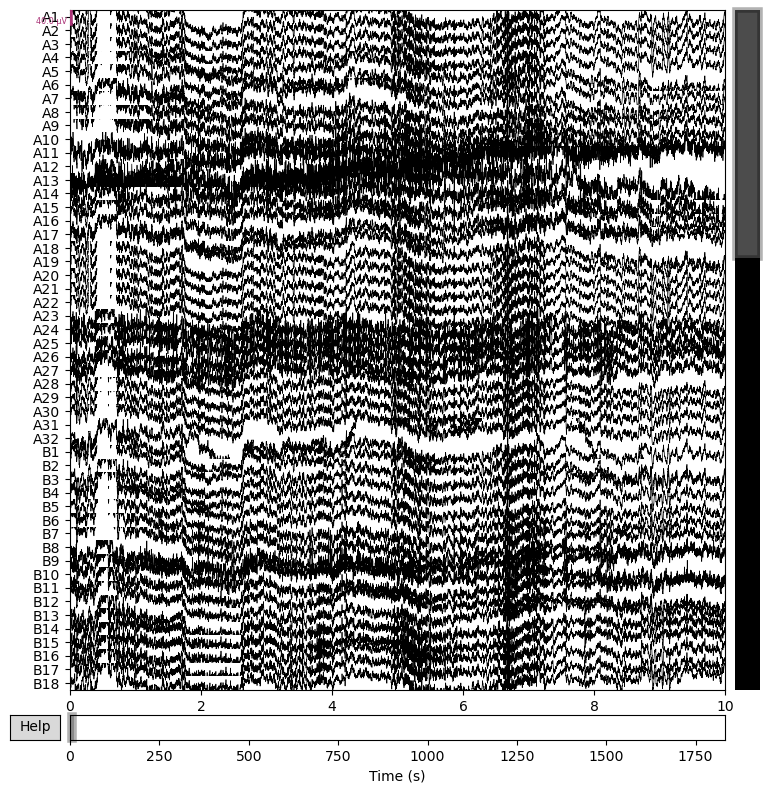

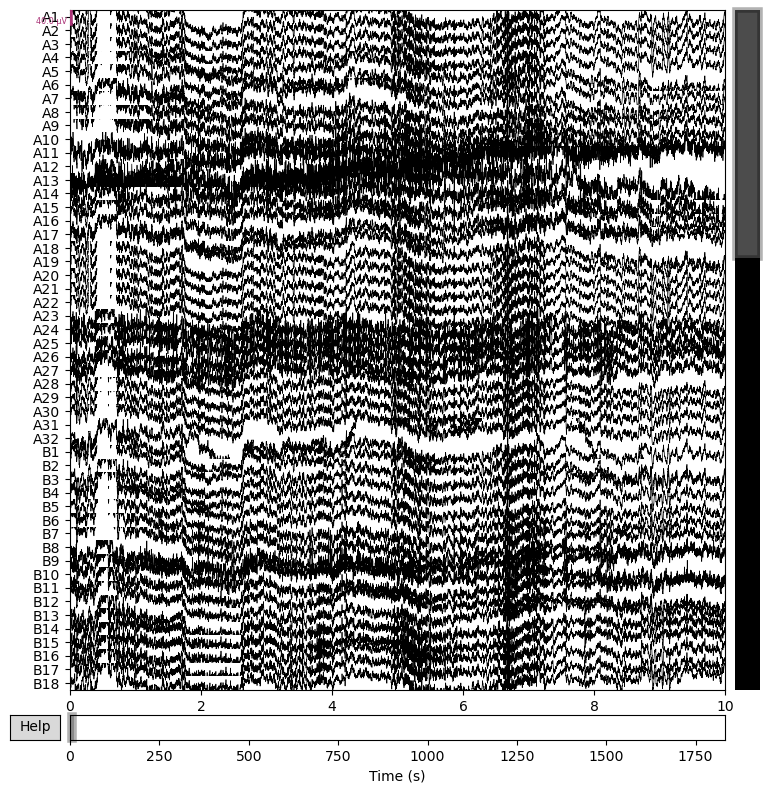

In [16]:
raw.plot(n_channels=50, title='EEG Raw Data (first 50 channels)')

In [17]:
# 0.5-100Hz Band-pass filter 적용
raw_bandpass = raw.filter(l_freq=0.5, h_freq=100)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 6759 samples (6.601 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.3s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.4s remaining:    0.0s
[Parallel(n_jobs=1)]: Done 136 out of 136 | elapsed:   20.2s finished


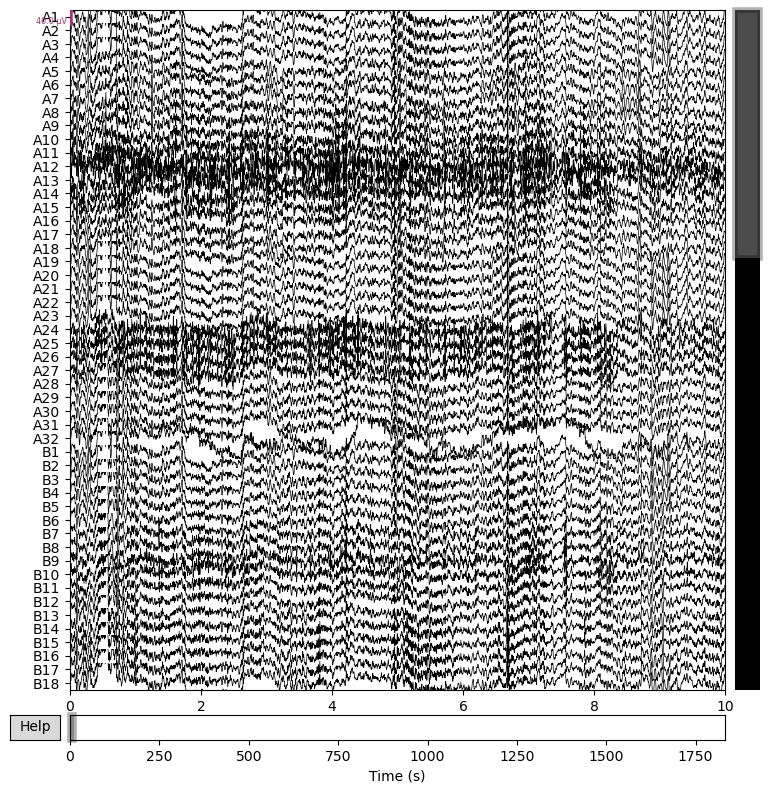

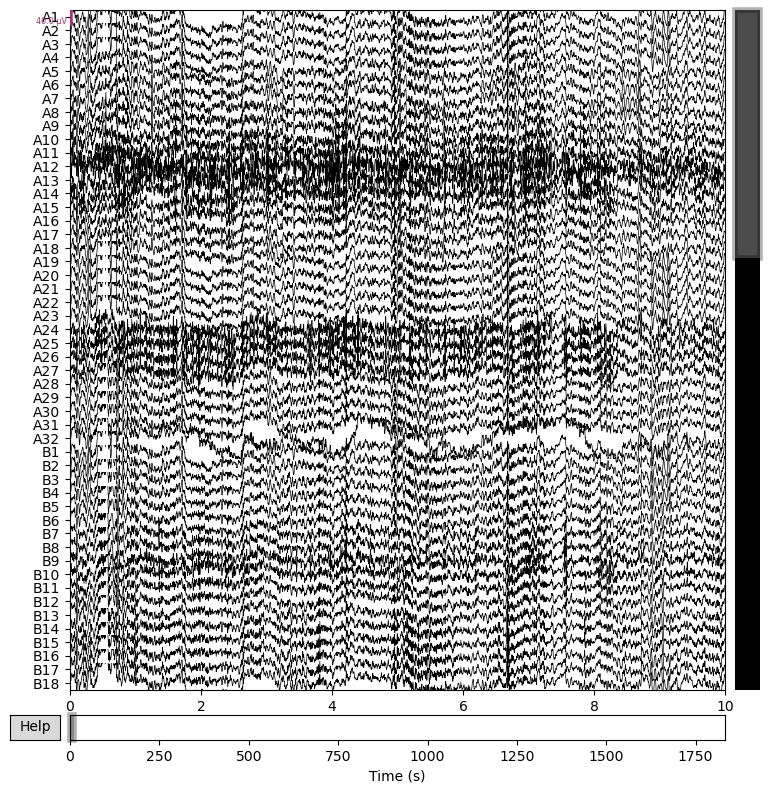

In [18]:
raw_bandpass.plot(n_channels=50, title='Filtered EEG Data (0.5-100 Hz)', show=True)

Effective window size : 2.000 (s)
Plotting power spectral density (dB=True).


C:\Users\windows\anaconda3\Lib\site-packages\mne\viz\utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


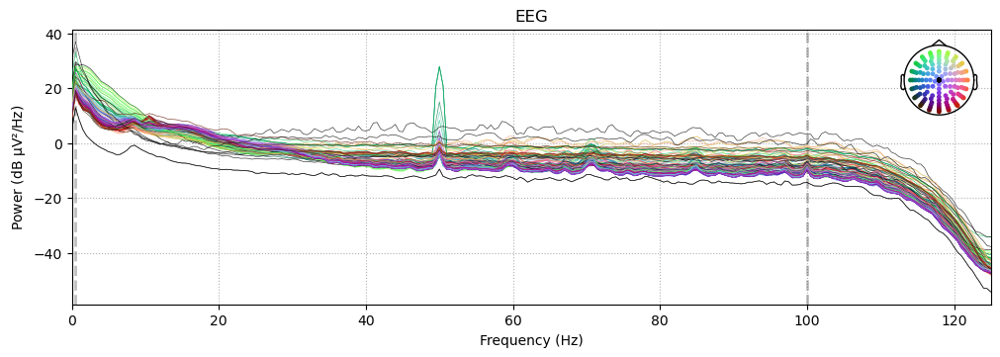

In [19]:
psd = raw_bandpass.compute_psd(fmax=125)
psd.plot()

In [20]:
# 50 Hz Notch-filter 적용
raw_notch = raw_bandpass.notch_filter(freqs=50)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge: 50.62 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 50.88 Hz)
- Filter length: 6759 samples (6.601 s)



[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.2s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.3s remaining:    0.0s
[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.4s remaining:    0.0s
[Parallel(n_jobs=1)]: Done 136 out of 136 | elapsed:   17.5s finished


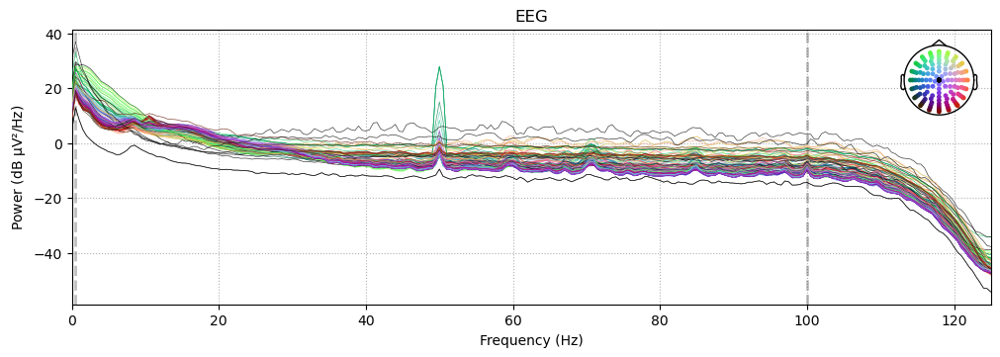

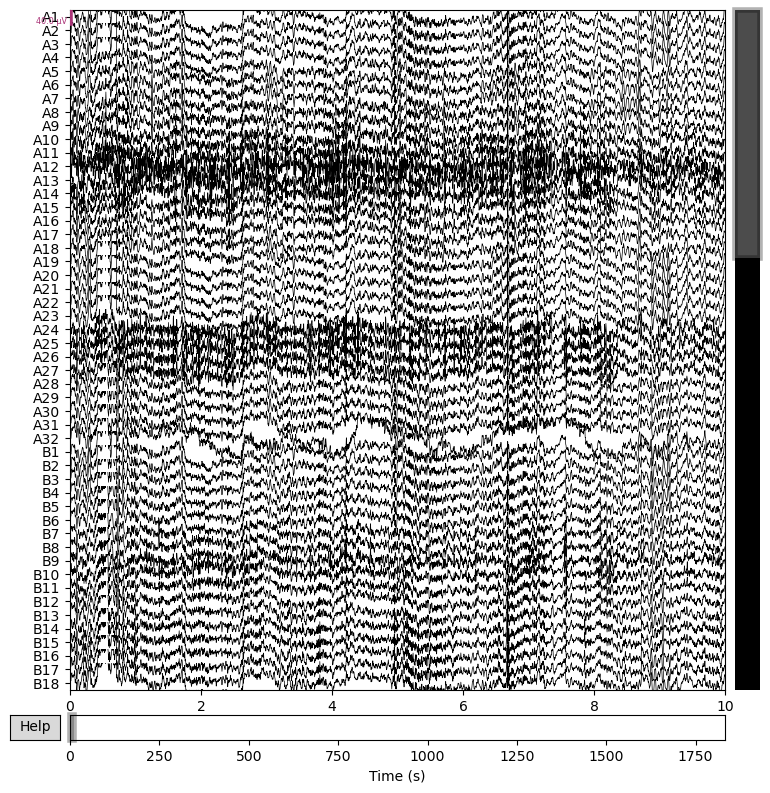

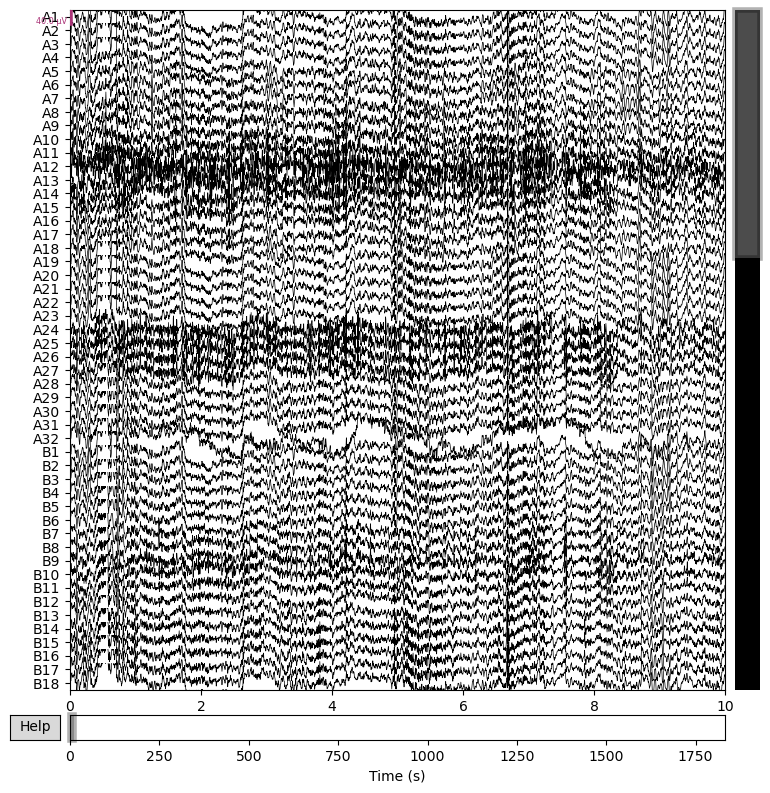

In [21]:
raw_notch.plot(n_channels=50, title='Filtered EEG Data (50 Hz)', show=True)

Effective window size : 2.000 (s)
Plotting power spectral density (dB=True).


C:\Users\windows\anaconda3\Lib\site-packages\mne\viz\utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


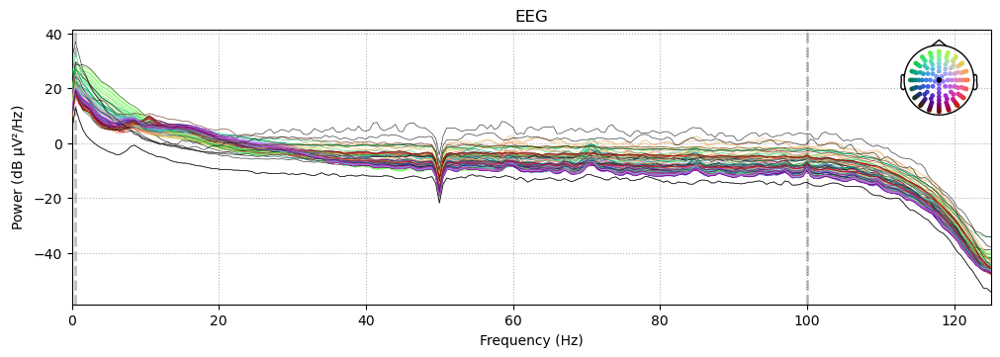

In [22]:
psd = raw_notch.compute_psd(fmax=125)
psd.plot()

In [23]:
# Sampling rate 출력
print(f"Sampling rate: {raw_notch.info['sfreq']} Hz")

Sampling rate: 1024.0 Hz


In [24]:
# Resampling
raw_resample = raw_notch.resample(sfreq=256)
raw_resample

Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1112 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]
Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1112 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]


<RawEDF | sub-01_ses-01_task-innerspeech_eeg.bdf, 137 x 468992 (1832.0 s), ~490.4 MiB, data loaded>

In [25]:
# Resampling 후 events 잘 변환되었는지 확인
events_resampled = mne.find_events(raw_resample, shortest_event=1)

print("Original events shape:", events.shape)
print("Resampled events shape:", events_resampled.shape)

print("Original events sample points (first 10):", events[:10,0])
print("Resampled events sample points (first 10):", events_resampled[:10,0])

Trigger channel Status has a non-zero initial value of 65536 (consider using initial_event=True to detect this event)
Removing orphaned offset at the beginning of the file.
1112 events found on stim channel Status
Event IDs: [11 12 13 14 15 16 17 21 22 23 31 32 33 34 42 44 45 46 51 61 62 63 64]
Original events shape: (1112, 3)
Resampled events shape: (1112, 3)
Original events sample points (first 10): [ 6283 16591 31976 36150 36171 39306 39869 40433 43044 44119]
Resampled events sample points (first 10): [ 1570  4147  7994  9037  9042  9826  9967 10108 10761 11029]


In [26]:
print(f"Sampling rate: {raw_resample.info['sfreq']} Hz")

Sampling rate: 256.0 Hz


In [27]:
# Epoching
event_id = {'arriba': 31, 'abajo': 32, 'derecha': 33, 'izquierda': 34}

# EEG 채널만 선택한 epoch 생성
exg_names = ['EXG1', 'EXG2', 'EXG3', 'EXG4', 'EXG5', 'EXG6', 'EXG7', 'EXG8']
eeg_names = [ch for ch in raw_resample.ch_names if ch not in exg_names]

eeg = raw_resample.copy().pick_channels(eeg_names)

epochs = mne.Epochs(eeg, events, event_id=event_id, tmin=0, tmax=4.5,
                    baseline=None, preload=True, reject=None, flat=None, reject_by_annotation=False)

NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Not setting metadata
200 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 200 events and 1153 original time points ...
146 bad epochs dropped


In [28]:
print(epochs._data.shape)

(54, 129, 1153)


Fitting ICA to data using 128 channels (please be patient, this may take a while)
Selecting by number: 128 components
Computing Extended Infomax ICA
Fitting ICA took 257.3s.


C:\Users\windows\AppData\Local\Temp\ipykernel_4252\289961010.py:6: RuntimeWarning: The provided Epochs instance is not filtered between 1 and 100 Hz. ICLabel was designed to classify features extracted from an EEG dataset bandpass filtered between 1 and 100 Hz (see the 'filter()' method for Raw and Epochs instances).
  ic_labels = label_components(epochs, ica, method='iclabel')  # eeg 또는 epochs 사용 가능


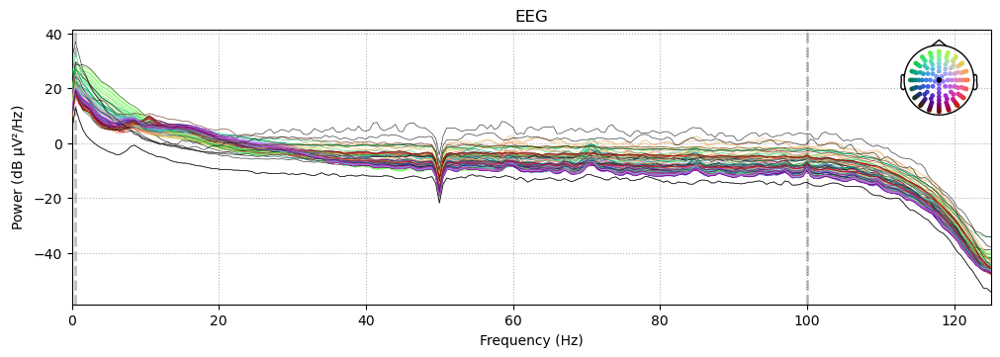

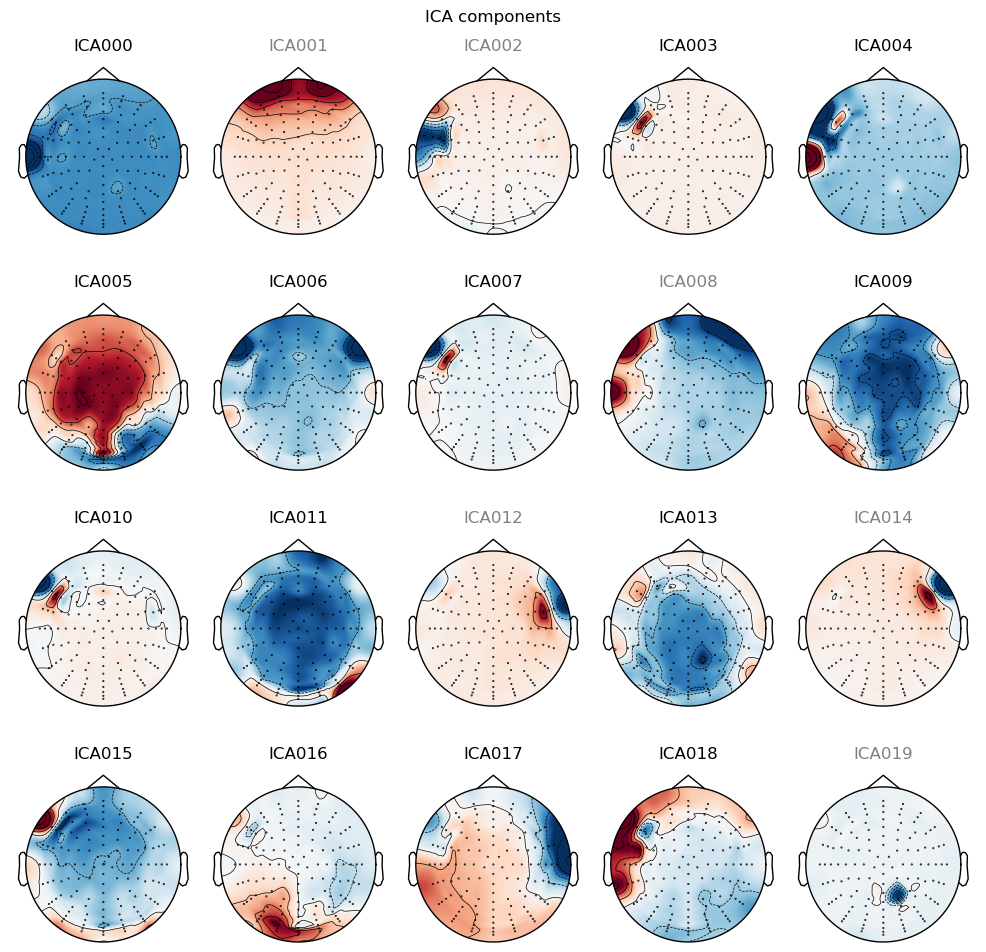

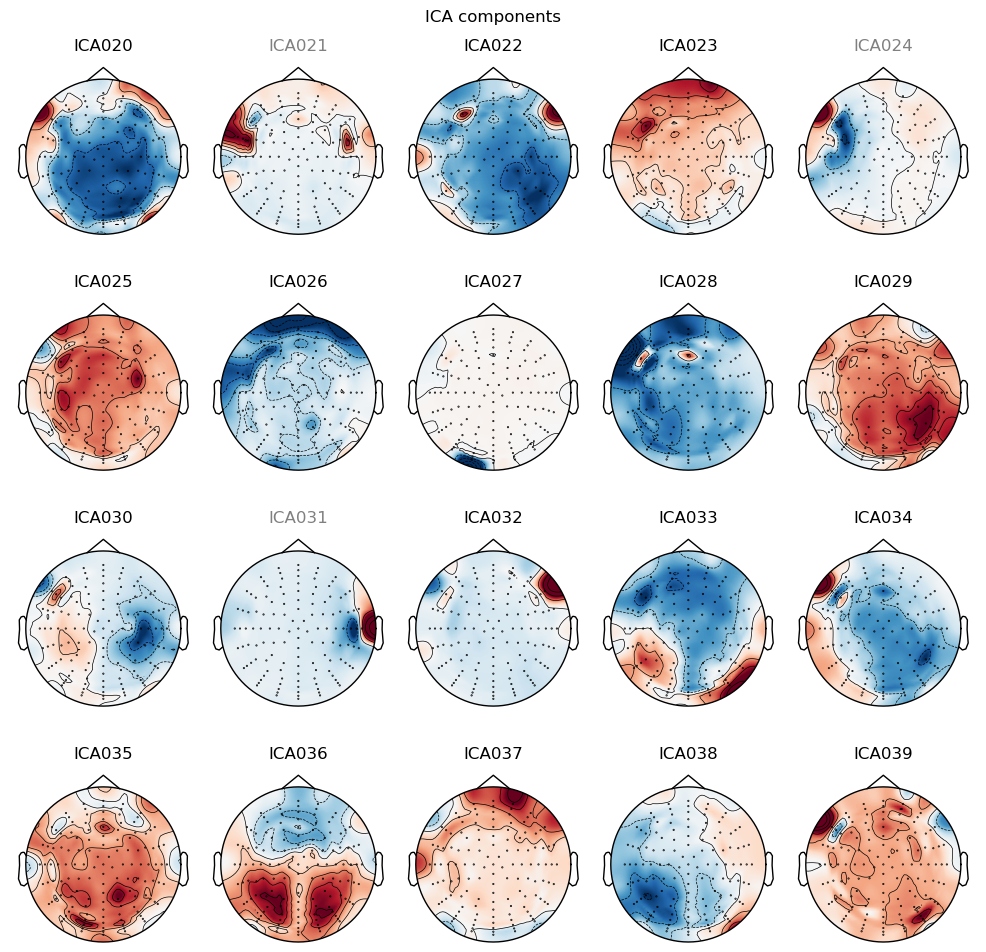

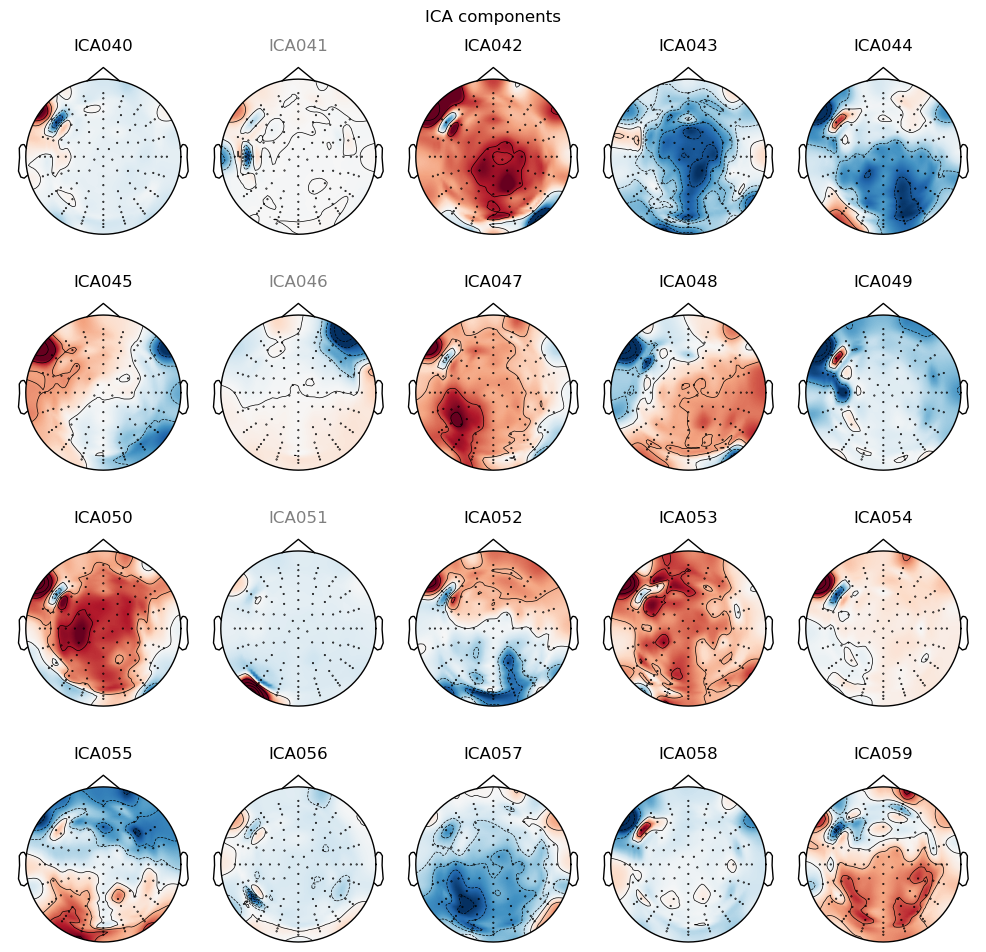

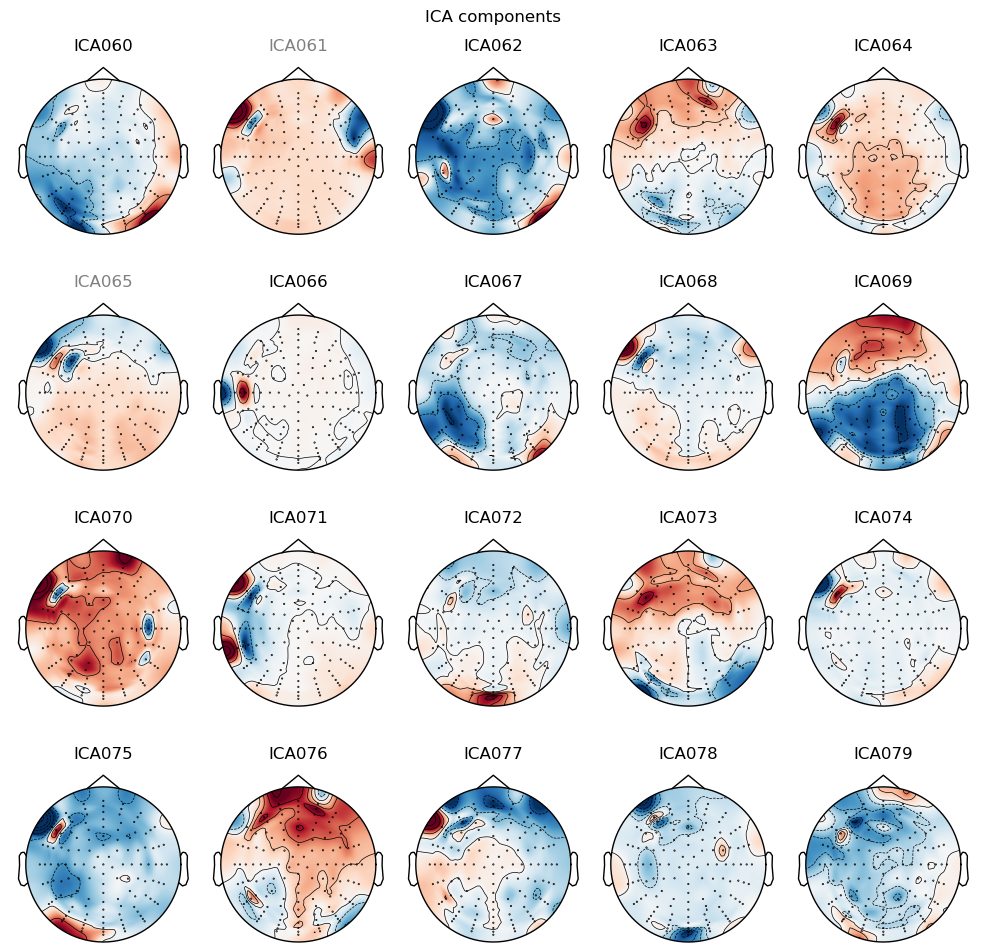

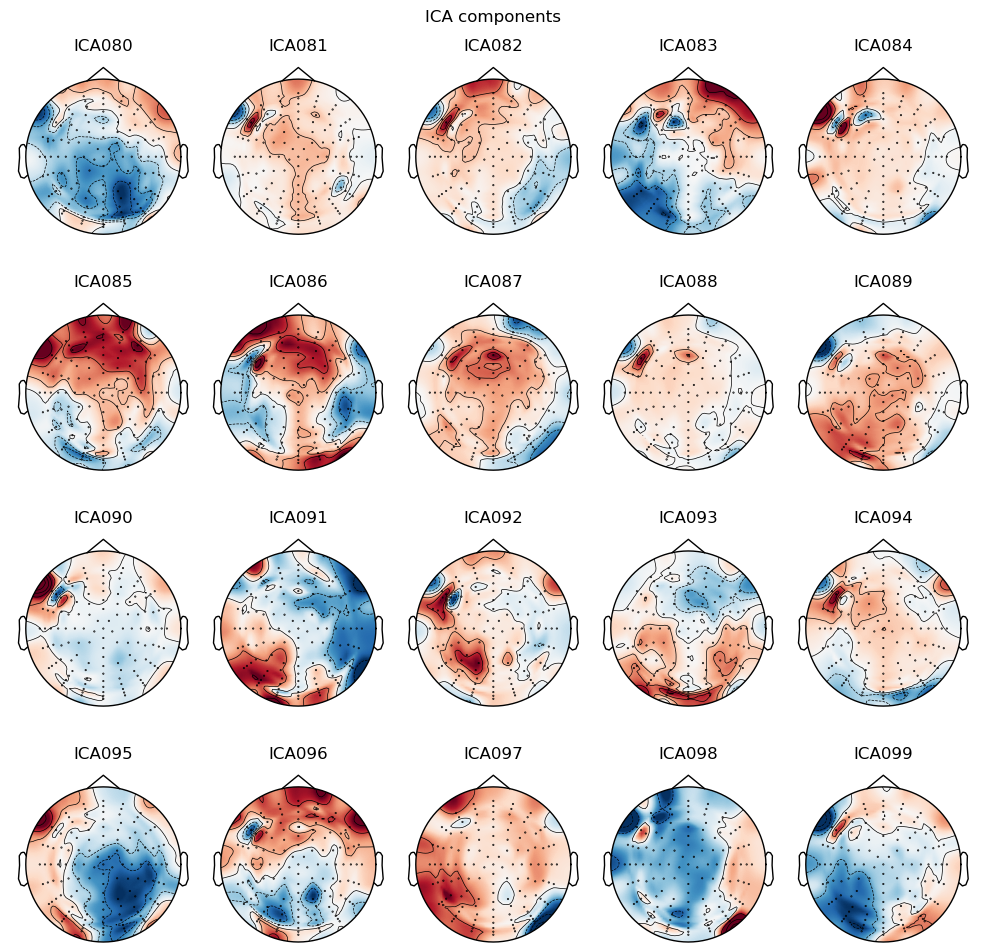

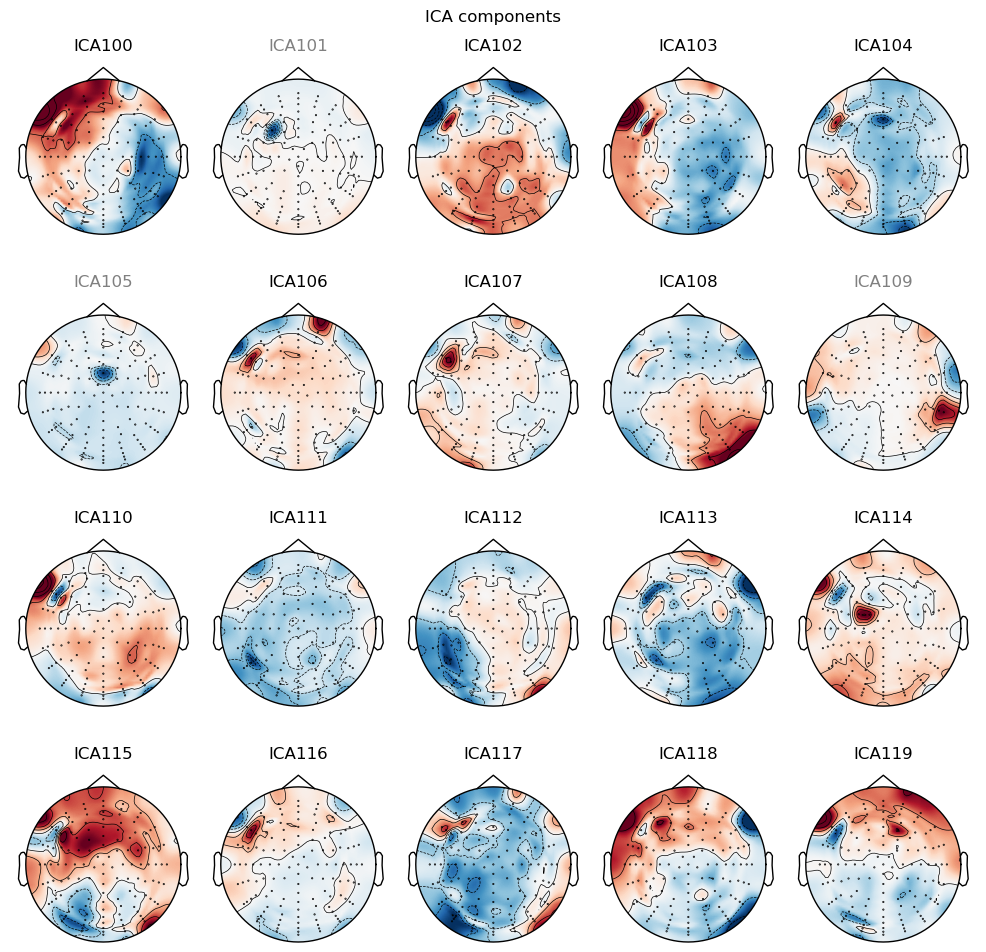

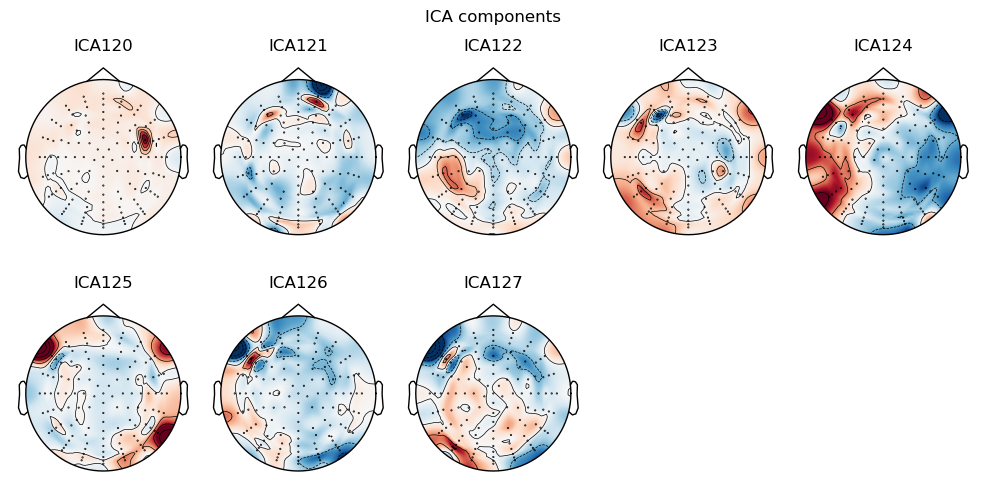

Applying ICA to Epochs instance
    Transforming to ICA space (128 components)
    Zeroing out 17 ICA components
    Projecting back using 128 PCA components
    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


C:\Users\windows\anaconda3\Lib\site-packages\mne\viz\utils.py:158: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


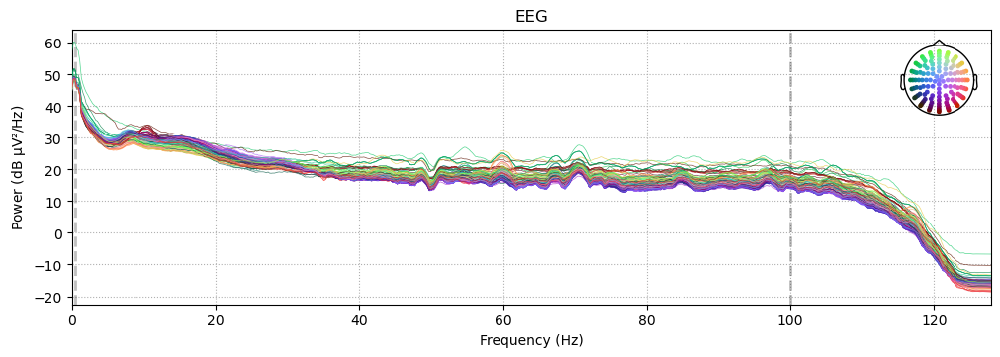

In [32]:
# ICA
ica = ICA(n_components=128, random_state=97, method='infomax', fit_params=dict(extended=True))
ica.fit(epochs)

# ICA 컴포넌트 자동 라벨링
ic_labels = label_components(epochs, ica, method='iclabel')  # eeg 또는 epochs 사용 가능

labels = ic_labels["labels"]

# 2. brain과 other 외 컴포넌트는 artifact로 판단해 제외
exclude_idx = [idx for idx, label in enumerate(labels) if label not in ['brain', 'other']]

ica.exclude = exclude_idx

# 3. 제외된 컴포넌트 시각화 (확인용)
ica.plot_components()

# 4. ICA 적용해 artifact 제거한 epoch 생성
clean_epochs = ica.apply(epochs.copy())

# 5. 결과 확인용 PSD 그리기
clean_epochs.compute_psd().plot()

In [33]:
# Epoch 개수 확인
print(f"Total number of epochs: {len(clean_epochs)}")

Total number of epochs: 54


In [34]:
clean_epochs.save('D:/Users/windows/Desktop/Inner Speech Decoding/Dataset/sub-01_ses-01_eeg-epo2.fif', overwrite=True)

C:\Users\windows\AppData\Local\Temp\ipykernel_4252\334922203.py:1: RuntimeWarning: This filename (D:/Users/windows/Desktop/Inner Speech Decoding/Dataset/sub-01_ses-01_eeg-epo2.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  clean_epochs.save('D:/Users/windows/Desktop/Inner Speech Decoding/Dataset/sub-01_ses-01_eeg-epo2.fif', overwrite=True)


[WindowsPath('D:/Users/windows/Desktop/Inner Speech Decoding/Dataset/sub-01_ses-01_eeg-epo2.fif')]